In [ ]:
import pygeoinf as inf 
import numpy as np
from typing import List, Any
import matplotlib.pyplot as plt
from aux import GridSpace, WaterMassForwardOperator, create_spatial_covariance_matrix

In [ ]:
# Definition of end members for source water types

# ASW: Arctic Surface Water
# sPW: Alaskan Coastal Current Water
# MsPW: Modified summer Pacific Water
# wPW: winter Pacific Water
# NCW: Norwegian Current Water
# AW: Atlantic Water
# BW: Brine-enriched Water

# T: ConservativeTemperature in degrees Celsius
# S: Absolute Salinity in g/kg
# O: Oxygen in umol/kg

end_members = {
    'ASW_T': -1.45, 
    'ASW_S': 27,
    'ASW_O': 390.53,
    'ASW_M': 1,
    'MsPW_T': 0.5, 
    'MsPW_S': 31,
    'MsPW_O': 354.21,
    'MsPW_M': 1,
    'sPW_T': 6,
    'sPW_S': 31.2,
    'sPW_O': 314,
    'sPW_M': 1,
    'wPW_T': -1.5,
    'wPW_S': 33.2,
    'wPW_O': 280.84,
    'wPW_M': 1,
    'NCW_T': 8, 
    'NCW_S': 35.4,
    'NCW_O': 287.82,
    'NCW_M': 1,
    'AW_T': 0.0, 
    'AW_S': 35.05,
    'AW_O': 298,
    'AW_M': 1,
    'BW_T': -1.8, 
    'BW_S': 34.45,
    'BW_O': 370,
    'BW_M': 1
}

In [ ]:
# Make a matrix using the end_members dictionary
mat = np.array([[end_members['ASW_T'], end_members['sPW_T'], end_members['MsPW_T'], end_members['wPW_T'], end_members['NCW_T'], end_members['AW_T'], end_members['BW_T']],
                [end_members['ASW_S'], end_members['sPW_S'], end_members['MsPW_S'], end_members['wPW_S'], end_members['NCW_S'], end_members['AW_S'], end_members['BW_S']],
                [end_members['ASW_O'], end_members['sPW_O'], end_members['MsPW_O'], end_members['wPW_O'], end_members['NCW_O'], end_members['AW_O'], end_members['BW_O']],
                [end_members['ASW_M'], end_members['sPW_M'], end_members['MsPW_M'], end_members['wPW_M'], end_members['NCW_M'], end_members['AW_M'], end_members['BW_M']]])

grid = GridSpace((30, 50))
problem = WaterMassForwardOperator(grid, mat)
forward_operator = problem.as_linear_operator()

data_error_measure = inf.GaussianMeasure.from_standard_deviation(grid, 0.001)
joint_data_error_measure = inf.GaussianMeasure.from_direct_sum([data_error_measure] * forward_operator.codomain.number_of_subspaces)

forward_problem = inf.LinearForwardProblem(forward_operator, data_error_measure=joint_data_error_measure)

In [ ]:
prior_covariance_matrix = create_spatial_covariance_matrix(grid.shape, 0.3, 2.0)
prior_expectation = np.full(grid.shape,  0.25)
prior_measure = inf.GaussianMeasure.from_covariance_matrix(grid, prior_covariance_matrix, expectation=prior_expectation)
joint_prior_measure = inf.GaussianMeasure.from_direct_sum([prior_measure] * forward_operator.domain.number_of_subspaces)

true_model, data = forward_problem.synthetic_model_and_data(joint_prior_measure)

# Set the last component of data to an array of ones as a conservation of mass constraint
data[-1] = np.ones(grid.shape)

inversion = inf.LinearBayesianInversion(forward_problem, joint_prior_measure)
solver = inf.CholeskySolver(galerkin=True)
posterior = inversion.model_posterior_measure(data, solver)

# Note: dim=1500 took 17m36s on tunya

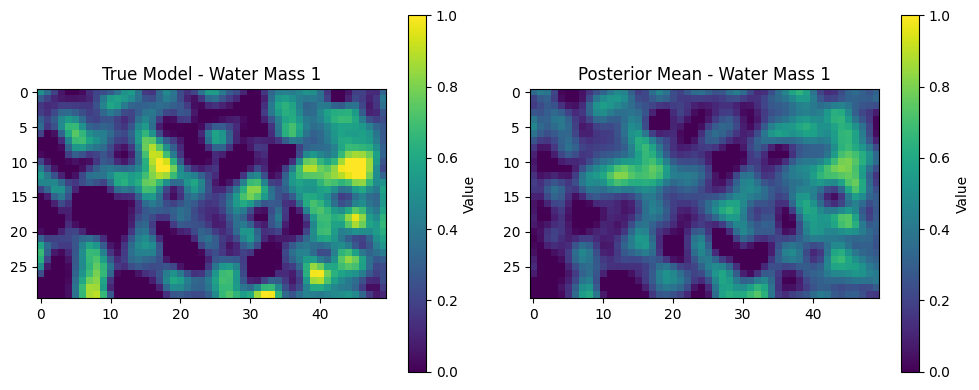

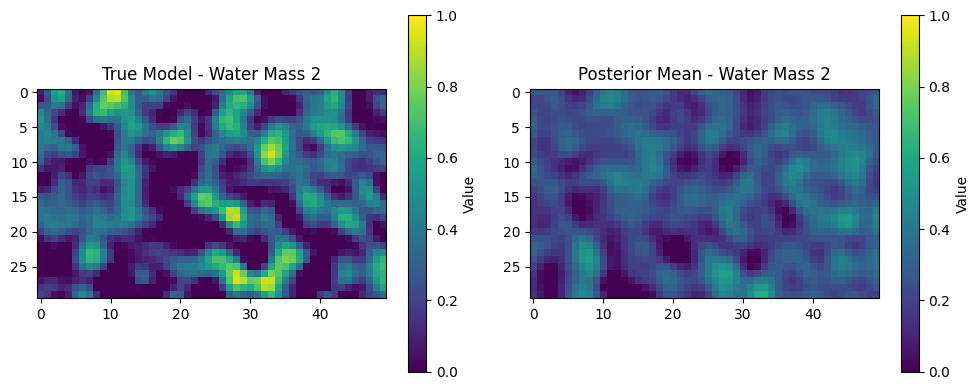

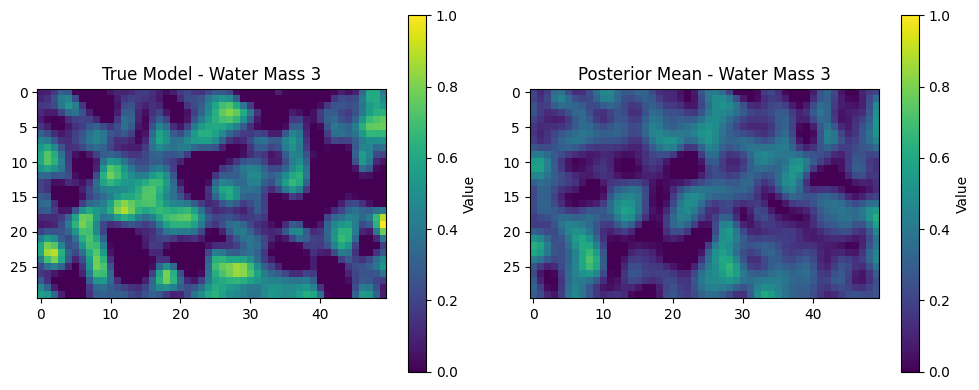

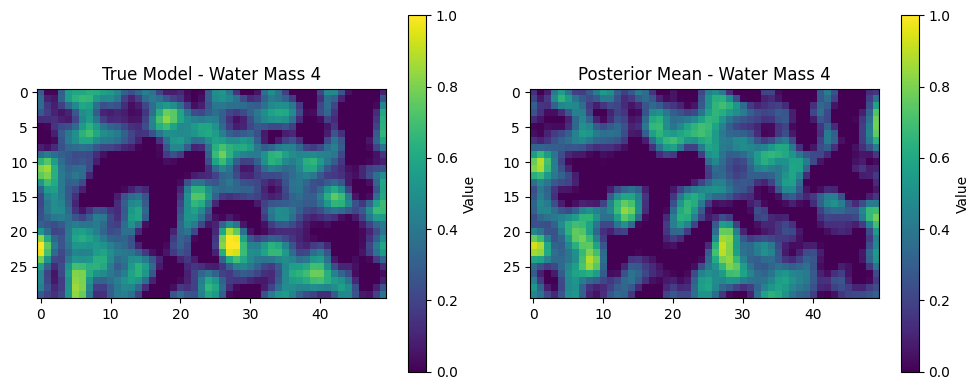

In [13]:
# Plot the results - each row is a water mass, and show true vs posterior mean
for i in range(mat.shape[1]):
    plt.figure(figsize=(10, 4))
    
    # True model
    plt.subplot(1, 2, 1)
    plt.title(f"True Model - Water Mass {i+1}")
    plt.imshow(true_model[i], cmap='viridis', vmin=0, vmax=1)
    plt.colorbar(label='Value')
    
    # Posterior mean
    plt.subplot(1, 2, 2)
    plt.title(f"Posterior Mean - Water Mass {i+1}")
    plt.imshow(posterior.expectation[i], cmap='viridis', vmin=0, vmax=1)
    plt.colorbar(label='Value')
    
    plt.tight_layout()